# 三种 Statistical Baseline 方法对比

本 notebook 用于比较当前项目中的三种 statistical baseline 方法：

- v1：小时级 contextual baseline
- v2a：15 分钟时间槽 baseline
- v2b：operation-aware threshold baseline

比较重点包括：方法差异、异常点数量、异常事件数量、不同变量/zone/运行时段的分布，以及三个方法检测到的异常点重叠情况。


## 1. 导入库与基础设置

本步骤导入 `pandas`、`numpy` 和 `matplotlib`，并设置中文字体。因为这个 notebook 主要用于解释和对比结果，所以不会重新计算 baseline，而是读取三个 baseline notebook 已经生成的输出表。


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 200)
plt.style.use("default")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def safe_print(*args) -> None:
    text = " ".join(str(arg) for arg in args)
    try:
        print(text)
    except UnicodeEncodeError:
        print(text.encode("ascii", errors="backslashreplace").decode("ascii"))


### 本步骤结果解释

这个 cell 只是准备分析环境，不产生研究结论。设置中文字体的原因是后续图表和 Markdown 解释都使用中文，避免图表标题或坐标轴出现乱码。

这里使用已有输出表进行比较，而不是重新跑三套 baseline，是为了保证 comparison notebook 对应的是已经验证过的 v1、v2a 和 v2b 结果。


## 2. 定义三个 baseline 版本和输出路径

这里明确记录每个版本的输出目录和方法含义。这样后续图表都可以追溯到具体的 baseline 方法。


In [2]:
NOTEBOOK_CWD = Path.cwd()

METHODS = {
    "v1_hourly": {
        "label": "v1 hourly",
        "description": "按 zone + day_type + hour + variable 建立 baseline，使用统一 robust z 阈值和 15 分钟持续时间。",
        "output_dir": NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_statistical_baseline",
    },
    "v2a_15min_slot": {
        "label": "v2a 15min slot",
        "description": "按 zone + day_type + 15min_slot + variable 建立更细时间粒度的 baseline。",
        "output_dir": NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_statistical_baseline_v2a_15min_slot",
    },
    "v2b_operation_aware": {
        "label": "v2b operation-aware",
        "description": "保留小时 baseline，但按运行时段、变量类型和持续时间规则调整异常判定，并增加 severity ranking。",
        "output_dir": NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_statistical_baseline_v2b_operation_aware",
    },
}

COMPARISON_DIR = NOTEBOOK_CWD / "outputs" / "floor6_zone1245_baseline_methods_comparison"
TABLE_DIR = COMPARISON_DIR / "comparison_tables"
FIGURE_DIR = COMPARISON_DIR / "comparison_figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for method_id, config in METHODS.items():
    if not config["output_dir"].exists():
        raise FileNotFoundError(f"Missing output directory for {method_id}: {config['output_dir']}")

safe_print("Comparison output:", COMPARISON_DIR)


Comparison output: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_comparison


### 本步骤结果解释

这个 cell 确认三个 baseline 版本的输出目录都存在，并创建一个新的 comparison 输出目录。

将 comparison 结果单独保存的原因是：v1、v2a 和 v2b 本身是三个独立实验版本，比较图和比较表属于跨版本分析，不应该混入任何单一 baseline 的结果目录。


## 3. 方法差异说明表

下面先用一张表概括三种 baseline 的核心差异。这个表适合直接放进报告中，用来解释为什么需要做多个 baseline 版本。


In [3]:
method_design = pd.DataFrame([
    {
        "method": "v1_hourly",
        "baseline_grouping": "zone + day_type + hour + variable",
        "threshold_rule": "统一 robust z >= 3.5；zero-aware rule 用于零值密集变量",
        "persistence_rule": "固定 15 分钟",
        "main_purpose": "建立稳定、可解释的第一版 statistical baseline",
    },
    {
        "method": "v2a_15min_slot",
        "baseline_grouping": "zone + day_type + 15min_slot + variable",
        "threshold_rule": "仍使用统一 robust z >= 3.5；zero-aware rule 保持与 v1 一致",
        "persistence_rule": "固定 15 分钟",
        "main_purpose": "测试更细时间粒度是否能捕捉小时内部变化",
    },
    {
        "method": "v2b_operation_aware",
        "baseline_grouping": "zone + day_type + hour + variable",
        "threshold_rule": "按运行时段调整阈值；非工作时间能源变量加强 zero-aware rule",
        "persistence_rule": "工作时间/环境变量 30 分钟，非工作时间能源异常 15 分钟",
        "main_purpose": "减少误报并突出更值得人工审查的异常事件",
    },
])

method_design.to_csv(TABLE_DIR / "01_method_design_comparison.csv", index=False)
display(method_design)


,method,baseline_grouping,threshold_rule,persistence_rule,main_purpose
0,v1_hourly,zone + day_type + hour + variable,统一 robust z >= 3.5；zero-aware rule 用于零值密集变量,固定 15 分钟,建立稳定、可解释的第一版 statistical baseline
1,v2a_15min_slot,zone + day_type + 15min_slot + variable,仍使用统一 robust z >= 3.5；zero-aware rule 保持与 v1 一致,固定 15 分钟,测试更细时间粒度是否能捕捉小时内部变化
2,v2b_operation_aware,zone + day_type + hour + variable,按运行时段调整阈值；非工作时间能源变量加强 zero-aware rule,工作时间/环境变量 30 分钟，非工作时间能源异常 15 分钟,减少误报并突出更值得人工审查的异常事件


### 本步骤结果解释

三种方法的差异可以概括为：

- v1 是基础版本，强调稳定和可解释。
- v2a 改变 baseline 的时间分组，把小时拆成 15 分钟时间槽，因此测试的是时间粒度敏感性。
- v2b 不改变 baseline profile 的小时分组，而是改变异常判定规则，因此测试的是运行逻辑和阈值规则敏感性。

这三种方法不是互相替代的关系，而是从不同角度检查异常检测结果是否可靠。


## 4. 读取三个版本的汇总结果

本步骤读取每个方法的 final validation、按变量汇总、按 zone 汇总、按运行时段汇总和异常点汇总表。


In [4]:
def read_first_matching(directory: Path, pattern: str) -> pd.DataFrame:
    matches = sorted(directory.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"No files matched {pattern} in {directory}")
    return pd.read_csv(matches[-1])


validation_frames = []
variable_event_frames = []
zone_event_frames = []
period_point_frames = []
variable_point_frames = []

for method_id, config in METHODS.items():
    table_dir = config["output_dir"] / "baseline_tables"
    validation = read_first_matching(table_dir, "*final_validation_summary.csv")
    validation["method"] = method_id
    validation["method_label"] = config["label"]
    validation_frames.append(validation)

    variable_events = pd.read_csv(table_dir / "13_summary_by_variable.csv")
    variable_events["method"] = method_id
    variable_events["method_label"] = config["label"]
    variable_event_frames.append(variable_events)

    zone_events = pd.read_csv(table_dir / "14_summary_by_zone.csv")
    zone_events["method"] = method_id
    zone_events["method_label"] = config["label"]
    zone_event_frames.append(zone_events)

    period_points = pd.read_csv(table_dir / "15_summary_by_operating_period.csv")
    period_points["method"] = method_id
    period_points["method_label"] = config["label"]
    period_point_frames.append(period_points)

    variable_points = pd.read_csv(table_dir / "10_final_anomaly_point_summary_by_variable.csv")
    variable_points["method"] = method_id
    variable_points["method_label"] = config["label"]
    variable_point_frames.append(variable_points)

validation_summary = pd.concat(validation_frames, ignore_index=True)
variable_event_summary = pd.concat(variable_event_frames, ignore_index=True)
zone_event_summary = pd.concat(zone_event_frames, ignore_index=True)
period_point_summary = pd.concat(period_point_frames, ignore_index=True)
variable_point_summary = pd.concat(variable_point_frames, ignore_index=True)

validation_summary.to_csv(TABLE_DIR / "02_validation_summary_all_methods.csv", index=False)
variable_event_summary.to_csv(TABLE_DIR / "03_variable_event_summary_all_methods.csv", index=False)
zone_event_summary.to_csv(TABLE_DIR / "04_zone_event_summary_all_methods.csv", index=False)
period_point_summary.to_csv(TABLE_DIR / "05_period_point_summary_all_methods.csv", index=False)
variable_point_summary.to_csv(TABLE_DIR / "06_variable_point_summary_all_methods.csv", index=False)

display(validation_summary[[
    "method", "rows_input_long", "baseline_profile_rows", "anomaly_points",
    "anomaly_events", "baseline_grouping", "table_count", "figure_count"
]])


,method,rows_input_long,baseline_profile_rows,anomaly_points,anomaly_events,baseline_grouping,table_count,figure_count
0,v1_hourly,2177184,1152,76773,940,zone + day_type + hour + variable,19,11
1,v2a_15min_slot,2177184,4608,84116,1248,zone + day_type + fifteen_minute_slot + variable,18,11
2,v2b_operation_aware,2177184,1152,48219,281,zone + day_type + hour + variable,19,12


### 本步骤结果解释

这个 cell 将三个版本的核心结果合并到统一表格中，方便直接比较。

从 final validation 可以看到：v1 和 v2b 的 baseline profile 都是 1,152 行，因为它们都按小时分组；v2a 的 baseline profile 是 4,608 行，因为它把一天拆成 96 个 15 分钟时间槽。

这种汇总方式的好处是可以把“方法差异”和“结果差异”对应起来，而不是只看某个单独 notebook 的输出。


## 5. 整体异常点和异常事件数量对比

下面比较三个方法检测到的 anomaly points 和 anomaly events。异常点是分钟级、变量级记录；异常事件是把连续异常点合并后的结果。


Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_comparison\comparison_figures\01_overall_anomaly_points_and_events.png


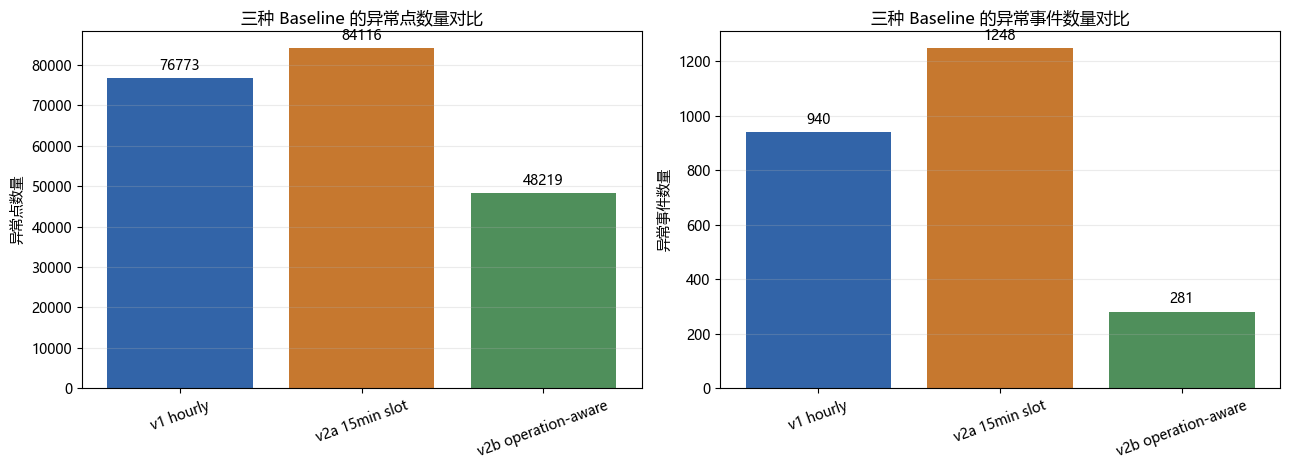

,method,method_label,anomaly_points,anomaly_events,baseline_profile_rows
0,v1_hourly,v1 hourly,76773,940,1152
1,v2a_15min_slot,v2a 15min slot,84116,1248,4608
2,v2b_operation_aware,v2b operation-aware,48219,281,1152


In [5]:
def save_current_figure(file_name: str) -> None:
    path = FIGURE_DIR / file_name
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    safe_print("Saved figure:", path)


overall = validation_summary[["method", "method_label", "anomaly_points", "anomaly_events", "baseline_profile_rows"]].copy()
overall.to_csv(TABLE_DIR / "07_overall_count_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = ["#3264a8", "#c6782f", "#4f8f5b"]

axes[0].bar(overall["method_label"], overall["anomaly_points"], color=colors)
axes[0].set_title("三种 Baseline 的异常点数量对比")
axes[0].set_ylabel("异常点数量")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(overall["method_label"], overall["anomaly_events"], color=colors)
axes[1].set_title("三种 Baseline 的异常事件数量对比")
axes[1].set_ylabel("异常事件数量")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.25)

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)

save_current_figure("01_overall_anomaly_points_and_events.png")
plt.show()

display(overall)


### 本步骤结果解释

整体结果显示，v2a 检测到的异常点和异常事件最多，因为 15 分钟时间槽 baseline 更精细，也更敏感。v2b 检测到的异常点和异常事件最少，因为它提高了工作时间阈值，并对工作时间和环境变量使用更长的持续时间要求。

因此，数量变化本身是符合预期的：

- v2a 适合检查“更细时间粒度是否会发现更多局部异常”。
- v2b 适合检查“更符合运行逻辑的规则是否能减少低优先级异常”。
- v1 作为中间参照，提供最稳定、最容易解释的基础结果。


## 5.1 三种方法异常点数量的单独对比图

上一张图同时展示了 anomaly points 和 anomaly events。为了更清楚地回答“三个方法分别检测到多少异常点”，这里单独绘制 anomaly points 对比图，并在每个柱子上直接标出具体数量和占全部 scoring rows 的比例。


Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_comparison\comparison_figures\05_anomaly_points_only_comparison.png


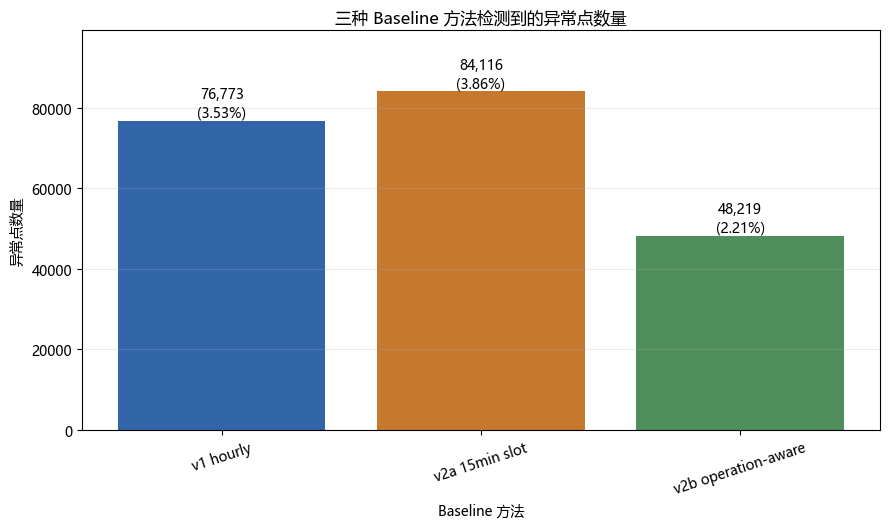

,method,method_label,rows_input_long,anomaly_points,anomaly_point_pct
0,v1_hourly,v1 hourly,2177184,76773,3.526252
1,v2a_15min_slot,v2a 15min slot,2177184,84116,3.863523
2,v2b_operation_aware,v2b operation-aware,2177184,48219,2.214742


In [6]:
points_only = validation_summary[[
    "method", "method_label", "rows_input_long", "anomaly_points"
]].copy()
points_only["anomaly_point_pct"] = points_only["anomaly_points"] / points_only["rows_input_long"] * 100
points_only.to_csv(TABLE_DIR / "08_anomaly_points_only_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5.4))
bars = ax.bar(points_only["method_label"], points_only["anomaly_points"], color=colors)
ax.set_title("三种 Baseline 方法检测到的异常点数量")
ax.set_xlabel("Baseline 方法")
ax.set_ylabel("异常点数量")
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=0.25)

for bar, (_, row) in zip(bars, points_only.iterrows()):
    label = f"{int(row['anomaly_points']):,}\n({row['anomaly_point_pct']:.2f}%)"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        label,
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_ylim(0, points_only["anomaly_points"].max() * 1.18)
save_current_figure("05_anomaly_points_only_comparison.png")
plt.show()

display(points_only)


### 本步骤结果解释

这张图直接比较三个 baseline 方法检测到的异常点数量：

- v1 hourly：76,773 个异常点，占全部 scoring rows 的约 3.53%。
- v2a 15min slot：84,116 个异常点，占约 3.86%，是三个方法中最多的。
- v2b operation-aware：48,219 个异常点，占约 2.21%，是三个方法中最少的。

这个结果符合方法设计：v2a 使用更细的 15 分钟时间槽，因此更敏感；v2b 使用运行时段阈值和动态持续时间规则，因此会过滤掉更多低优先级异常点。


## 6. 按变量对比异常点和异常事件

本步骤比较不同变量在三种 baseline 方法下的异常数量。这样可以看出方法变化主要影响哪些字段。


Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_comparison\comparison_figures\02_variable_level_comparison.png


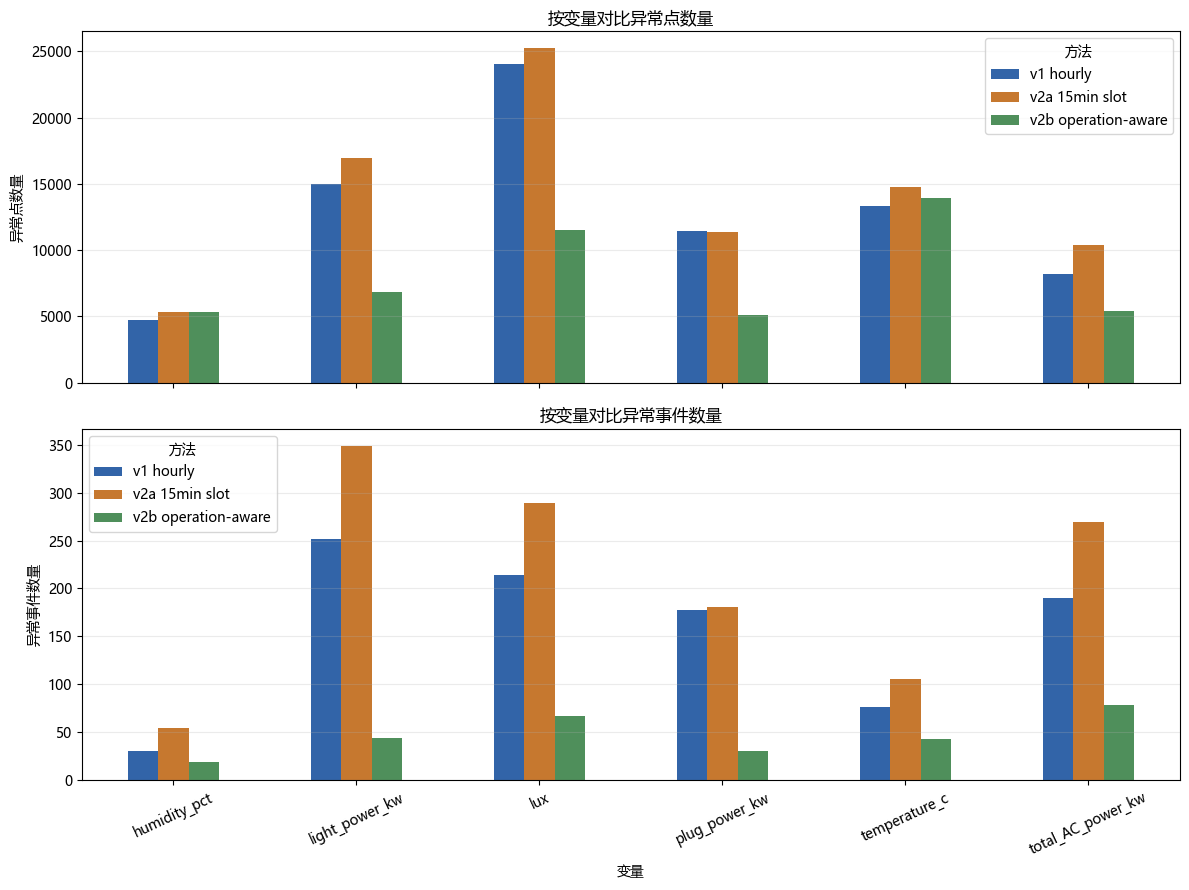

method_label,v1 hourly,v2a 15min slot,v2b operation-aware
variable,,,
humidity_pct,4719,5348,5361
light_power_kw,15028,16975,6874
lux,24061,25255,11532
plug_power_kw,11419,11359,5128
temperature_c,13327,14780,13908
total_AC_power_kw,8219,10399,5416


method_label,v1 hourly,v2a 15min slot,v2b operation-aware
variable,,,
humidity_pct,30,54,19
light_power_kw,252,349,44
lux,214,289,67
plug_power_kw,178,181,30
temperature_c,76,106,43
total_AC_power_kw,190,269,78


In [7]:
method_order = [config["label"] for config in METHODS.values()]

variable_points_pivot = (
    variable_point_summary
    .pivot_table(index="variable", columns="method_label", values="anomaly_points", aggfunc="sum", fill_value=0)
    .reindex(columns=method_order)
)
variable_events_pivot = (
    variable_event_summary
    .pivot_table(index="variable", columns="method_label", values="events", aggfunc="sum", fill_value=0)
    .reindex(columns=method_order)
)

variable_points_pivot.to_csv(TABLE_DIR / "08_variable_anomaly_points_pivot.csv")
variable_events_pivot.to_csv(TABLE_DIR / "09_variable_anomaly_events_pivot.csv")

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
variable_points_pivot.plot(kind="bar", ax=axes[0], color=colors)
axes[0].set_title("按变量对比异常点数量")
axes[0].set_ylabel("异常点数量")
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="方法")

variable_events_pivot.plot(kind="bar", ax=axes[1], color=colors)
axes[1].set_title("按变量对比异常事件数量")
axes[1].set_ylabel("异常事件数量")
axes[1].set_xlabel("变量")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(title="方法")

save_current_figure("02_variable_level_comparison.png")
plt.show()

display(variable_points_pivot)
display(variable_events_pivot)


### 本步骤结果解释

按变量比较可以看出，v2a 对 `lux`、`light_power_kw` 和 `total_AC_power_kw` 更敏感，因为这些变量在日内不同 15 分钟时间槽中的变化更明显。

v2b 通常会减少事件数量，尤其是工作时间中的短暂波动。这是因为 v2b 对工作时段采用更高阈值和更长持续时间要求。它的目的不是发现最多异常，而是筛出更值得人工检查的异常。


## 7. 按 Zone 和运行时段对比

本步骤比较异常是否集中在某些 zone 或运行时段。这个分析可以帮助判断异常是空间问题、时间问题，还是方法本身敏感性导致的结果差异。


Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_comparison\comparison_figures\03_zone_and_period_comparison.png


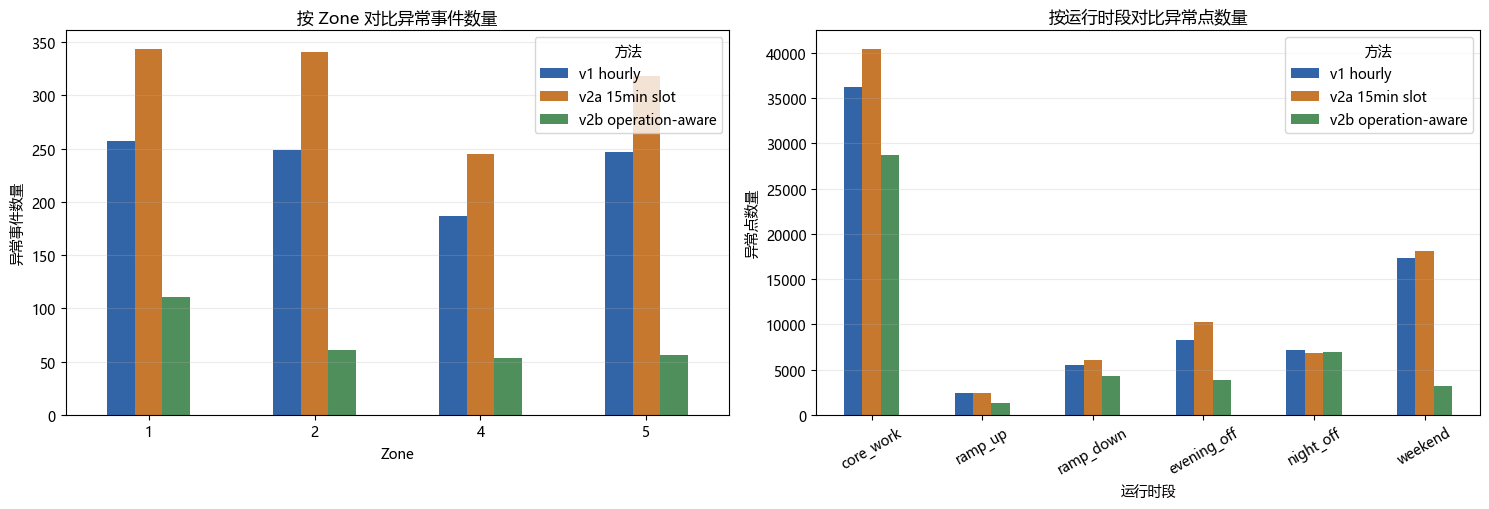

method_label,v1 hourly,v2a 15min slot,v2b operation-aware
zone,,,
1,257,344,111
2,249,341,61
4,187,245,53
5,247,318,56


method_label,v1 hourly,v2a 15min slot,v2b operation-aware
operating_period,,,
core_work,36201,40490,28691
ramp_up,2453,2350,1290
ramp_down,5495,6074,4287
evening_off,8224,10227,3882
night_off,7117,6879,6899
weekend,17283,18096,3170


In [8]:
zone_events_pivot = (
    zone_event_summary
    .pivot_table(index="zone", columns="method_label", values="events", aggfunc="sum", fill_value=0)
    .reindex(columns=method_order)
)
period_points_pivot = (
    period_point_summary
    .pivot_table(index="operating_period", columns="method_label", values="anomaly_points", aggfunc="sum", fill_value=0)
    .reindex(columns=method_order)
)

period_order = ["core_work", "ramp_up", "ramp_down", "evening_off", "night_off", "weekend"]
period_points_pivot = period_points_pivot.reindex(period_order)

zone_events_pivot.to_csv(TABLE_DIR / "10_zone_event_comparison.csv")
period_points_pivot.to_csv(TABLE_DIR / "11_period_point_comparison.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
zone_events_pivot.plot(kind="bar", ax=axes[0], color=colors)
axes[0].set_title("按 Zone 对比异常事件数量")
axes[0].set_ylabel("异常事件数量")
axes[0].set_xlabel("Zone")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="方法")

period_points_pivot.plot(kind="bar", ax=axes[1], color=colors)
axes[1].set_title("按运行时段对比异常点数量")
axes[1].set_ylabel("异常点数量")
axes[1].set_xlabel("运行时段")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(title="方法")

save_current_figure("03_zone_and_period_comparison.png")
plt.show()

display(zone_events_pivot)
display(period_points_pivot)


### 本步骤结果解释

按 zone 的对比可以判断异常是否集中在某些空间区域。若三个方法都显示同一个 zone 异常较多，说明该区域更值得后续检查。

按运行时段的对比尤其重要，因为楼宇能耗存在明显工作/非工作时间差异。v2b 对工作时间更严格地减少误报，对非工作时间能源异常保持敏感，因此它的运行时段分布通常会比 v1 和 v2a 更偏向高优先级事件。


## 8. 三种方法异常点重叠对比

本步骤读取三个版本的 anomaly score 表，只保留最终 `is_anomaly=True` 的点，然后按 `timestamp + zone + variable` 比较三个方法检测到的异常点是否重叠。


C:\Users\jh\AppData\Local\Temp\ipykernel_35032\2923840561.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  overlap[method_id] = overlap[method_id].fillna(False).astype(bool)
C:\Users\jh\AppData\Local\Temp\ipykernel_35032\2923840561.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  overlap[method_id] = overlap[method_id].fillna(False).astype(bool)
C:\Users\jh\AppData\Local\Temp\ipykernel_35032\2923840561.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.in

Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_comparison\comparison_figures\04_anomaly_point_overlap_comparison.png


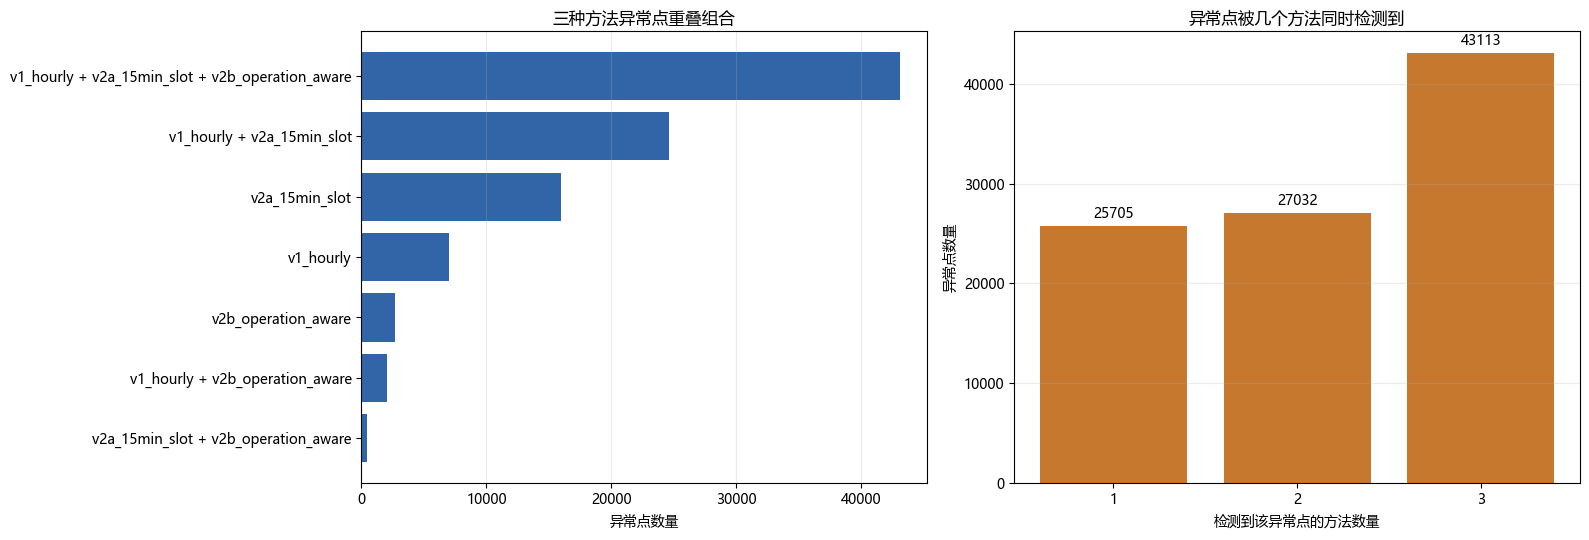

,combination,anomaly_points
2,v1_hourly + v2a_15min_slot + v2b_operation_aware,43113
1,v1_hourly + v2a_15min_slot,24610
4,v2a_15min_slot,15984
0,v1_hourly,7037
6,v2b_operation_aware,2684
3,v1_hourly + v2b_operation_aware,2013
5,v2a_15min_slot + v2b_operation_aware,409


,detected_by_count,anomaly_points
0,1,25705
1,2,27032
2,3,43113


In [9]:
def load_anomaly_point_keys(method_id: str, config: dict) -> pd.DataFrame:
    score_path = config["output_dir"] / "baseline_tables" / "09_baseline_anomaly_scores_long.csv.gz"
    usecols = ["timestamp", "zone", "variable", "is_anomaly"]
    frame = pd.read_csv(score_path, usecols=usecols, parse_dates=["timestamp"])
    frame = frame.loc[frame["is_anomaly"], ["timestamp", "zone", "variable"]].copy()
    frame[method_id] = True
    return frame


overlap = None
for method_id, config in METHODS.items():
    keys = load_anomaly_point_keys(method_id, config)
    if overlap is None:
        overlap = keys
    else:
        overlap = overlap.merge(keys, on=["timestamp", "zone", "variable"], how="outer")

for method_id in METHODS:
    overlap[method_id] = overlap[method_id].fillna(False).astype(bool)

overlap["detected_by_count"] = overlap[list(METHODS.keys())].sum(axis=1)
overlap["combination"] = overlap[list(METHODS.keys())].apply(
    lambda row: " + ".join([method for method, detected in row.items() if detected]),
    axis=1,
)

overlap_summary = (
    overlap.groupby("combination")
    .agg(anomaly_points=("timestamp", "size"))
    .reset_index()
    .sort_values("anomaly_points", ascending=False)
)
overlap_count_summary = (
    overlap.groupby("detected_by_count")
    .agg(anomaly_points=("timestamp", "size"))
    .reset_index()
    .sort_values("detected_by_count")
)

overlap.to_csv(TABLE_DIR / "12_anomaly_point_overlap_detail.csv", index=False)
overlap_summary.to_csv(TABLE_DIR / "13_anomaly_point_overlap_by_combination.csv", index=False)
overlap_count_summary.to_csv(TABLE_DIR / "14_anomaly_point_overlap_by_method_count.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].barh(overlap_summary["combination"], overlap_summary["anomaly_points"], color="#3264a8")
axes[0].set_title("三种方法异常点重叠组合")
axes[0].set_xlabel("异常点数量")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.25)

axes[1].bar(overlap_count_summary["detected_by_count"].astype(str), overlap_count_summary["anomaly_points"], color="#c6782f")
axes[1].set_title("异常点被几个方法同时检测到")
axes[1].set_xlabel("检测到该异常点的方法数量")
axes[1].set_ylabel("异常点数量")
axes[1].grid(axis="y", alpha=0.25)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=3)

save_current_figure("04_anomaly_point_overlap_comparison.png")
plt.show()

display(overlap_summary)
display(overlap_count_summary)


### 本步骤结果解释

重叠分析比单纯比较总数更有价值。被三个方法同时检测到的异常点通常更稳定，因为它们不依赖某一个特定阈值或时间分组。只被 v2a 检测到的点，可能代表更细时间槽带来的局部异常，也可能包含更多敏感性导致的误报。只被 v2b 检测到的点，则可能与非工作时间能源规则或动态阈值有关。

因此，后续报告可以把“三个方法共同发现的异常”作为高可信候选，把“只被某一个方法发现的异常”作为 sensitivity analysis 的讨论内容。


## 9. 输出最终比较总结

最后生成一张 summary 表，汇总三个方法的主要数量结果和解释重点。


In [10]:
comparison_summary = overall.merge(
    method_design[["method", "baseline_grouping", "threshold_rule", "persistence_rule", "main_purpose"]],
    on="method",
    how="left",
)
comparison_summary = comparison_summary[[
    "method", "method_label", "baseline_grouping", "anomaly_points", "anomaly_events",
    "baseline_profile_rows", "threshold_rule", "persistence_rule", "main_purpose",
]]
comparison_summary.to_csv(TABLE_DIR / "15_final_baseline_method_comparison_summary.csv", index=False)

safe_print("Comparison tables:", TABLE_DIR)
safe_print("Comparison figures:", FIGURE_DIR)
display(comparison_summary)


Comparison tables: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_comparison\comparison_tables
Comparison figures: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_comparison\comparison_figures


,method,method_label,baseline_grouping,anomaly_points,anomaly_events,baseline_profile_rows,threshold_rule,persistence_rule,main_purpose
0,v1_hourly,v1 hourly,zone + day_type + hour + variable,76773,940,1152,统一 robust z >= 3.5；zero-aware rule 用于零值密集变量,固定 15 分钟,建立稳定、可解释的第一版 statistical baseline
1,v2a_15min_slot,v2a 15min slot,zone + day_type + 15min_slot + variable,84116,1248,4608,仍使用统一 robust z >= 3.5；zero-aware rule 保持与 v1 一致,固定 15 分钟,测试更细时间粒度是否能捕捉小时内部变化
2,v2b_operation_aware,v2b operation-aware,zone + day_type + hour + variable,48219,281,1152,按运行时段调整阈值；非工作时间能源变量加强 zero-aware rule,工作时间/环境变量 30 分钟，非工作时间能源异常 15 分钟,减少误报并突出更值得人工审查的异常事件


### 本步骤结果解释

最终比较表说明：

- v1 是基础可解释 baseline，适合作为主参照。
- v2a 使用 15 分钟时间槽，异常数量更多，说明它对小时内部变化更敏感。
- v2b 使用运行逻辑调整阈值和持续时间，异常数量更少，说明它更适合筛选高优先级异常候选。

因此，报告中可以把 v1 作为 primary statistical baseline，把 v2a 和 v2b 作为 sensitivity comparison。这样既能证明结果不是单一参数造成的，也能解释不同规则下异常数量变化的原因。
